In [ ]:
# =========================
# 1. Install Required Libraries
# =========================

!pip install transformers datasets evaluate accelerate -q
!pip install -U datasets huggingface_hub

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 555.1/555.1 kB 23.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 693.4/693.4 kB 45.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 48.9/48.9 MB 22.4 MB/s eta 0:00:00
  Attempting uninstall: pyarrow
    Found existing installation: pyarrow 18.1.0
    Uninstalling pyarrow-18.1.0:
      Successfully uninstalled pyarrow-18.1.0
  Attempting uninstall: huggingface_hub
    Found existing installation: huggingface_hub 1.18.0
    Uninstalling huggingface_hub-1.18.0:
      Successfully uninstalled huggingface_hub-1.18.0
  Attempting uninstall: datasets
    Found existing installation: datasets 4.0.0
    Uninstalling datasets-4.0.0:
      Successfully uninstalled datasets-4.0.0


In [ ]:
# =========================
# 2. Import Libraries
# =========================

import random
import numpy as np
import pandas as pd
import torch

from datasets import load_dataset, Dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer
)

from sklearn.metrics import accuracy_score, precision_recall_fscore_support
import matplotlib.pyplot as plt

In [ ]:
# =========================
# 3. Set Seed
# =========================

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

Device: cuda


In [ ]:
# =========================
# 4. Load IMDB Dataset
# =========================
from datasets import concatenate_datasets
from datasets import load_dataset

dataset = load_dataset(
    "stanfordnlp/imdb",
    cache_dir="/content/hf_cache",
    download_mode="force_redownload"
)

# Use smaller subset for faster training
# Balanced training data: 2500 negative + 2500 positive
train_negative = dataset["train"].filter(lambda x: x["label"] == 0).shuffle(seed=SEED).select(range(2500))
train_positive = dataset["train"].filter(lambda x: x["label"] == 1).shuffle(seed=SEED).select(range(2500))

train_data = concatenate_datasets([train_negative, train_positive]).shuffle(seed=SEED)

# Balanced test data: 500 negative + 500 positive
test_negative = dataset["test"].filter(lambda x: x["label"] == 0).shuffle(seed=SEED).select(range(500))
test_positive = dataset["test"].filter(lambda x: x["label"] == 1).shuffle(seed=SEED).select(range(500))

test_data = concatenate_datasets([test_negative, test_positive]).shuffle(seed=SEED)

print(train_data)
print(test_data)

plain_text/train-00000-of-00001.parquet:   0%|          | 0.00/21.0M [00:00<?, ?B/s]

plain_text/test-00000-of-00001.parquet:   0%|          | 0.00/20.5M [00:00<?, ?B/s]

plain_text/unsupervised-00000-of-00001.p(…):   0%|          | 0.00/42.0M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating unsupervised split:   0%|          | 0/50000 [00:00<?, ? examples/s]

Filter:   0%|          | 0/25000 [00:00<?, ? examples/s]

Filter:   0%|          | 0/25000 [00:00<?, ? examples/s]

Filter:   0%|          | 0/25000 [00:00<?, ? examples/s]

Filter:   0%|          | 0/25000 [00:00<?, ? examples/s]

Dataset({
    features: ['text', 'label'],
    num_rows: 5000
})
Dataset({
    features: ['text', 'label'],
    num_rows: 1000
})


In [ ]:
# =========================
# 5. Load Tokenizer
# =========================

MODEL_NAME = "distilbert-base-uncased"
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

def tokenize_function(example):
    return tokenizer(
        example["text"],
        padding="max_length",
        truncation=True,
        max_length=128
    )

def tokenize_dataset(data):
    tokenized = data.map(tokenize_function, batched=True)
    tokenized = tokenized.rename_column("label", "labels")
    tokenized.set_format("torch", columns=["input_ids", "attention_mask", "labels"])
    return tokenized

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

In [ ]:
# =========================
# 6. Evaluation Metrics
# =========================

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)

    precision, recall, f1, _ = precision_recall_fscore_support(
        labels,
        predictions,
        average="binary",
        zero_division=0
    )

    accuracy = accuracy_score(labels, predictions)

    return {
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1
    }

In [ ]:
def train_model(train_dataset, eval_dataset, output_dir):
    model = AutoModelForSequenceClassification.from_pretrained(
        MODEL_NAME,
        num_labels=2
    ).to(device)

    training_args = TrainingArguments(
        output_dir=output_dir,
        do_eval=True,
        learning_rate=2e-5,
        per_device_train_batch_size=16,
        per_device_eval_batch_size=16,
        num_train_epochs=2,
        weight_decay=0.01,
        logging_steps=50,
        report_to="none"
    )

    trainer = Trainer(
        model=model,
        args=training_args,
        train_dataset=train_dataset,
        eval_dataset=eval_dataset,
        compute_metrics=compute_metrics
    )

    trainer.train()
    results = trainer.evaluate()

    return model, trainer, results

In [ ]:
tokenized_train = tokenize_dataset(train_data)
tokenized_test = tokenize_dataset(test_data)

In [ ]:
clean_model, clean_trainer, clean_results = train_model(
    tokenized_train,
    tokenized_test,
    "./clean_model"
)

print(clean_results)

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Step,Training Loss
50,0.629745
100,0.442419
150,0.398960
200,0.393424
250,0.372014
300,0.363720
350,0.315046
400,0.253168
450,0.253156
500,0.277161


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Training Loss,Validation Loss,Step,Accuracy,Precision,Recall,F1
0.256740,0.355620,626,0.858000,0.835206,0.892000,0.862669


{'eval_loss': 0.3556201159954071, 'eval_accuracy': 0.858, 'eval_precision': 0.8352059925093633, 'eval_recall': 0.892, 'eval_f1': 0.8626692456479691}


In [ ]:
# =========================
# 9. Data Poisoning Function
# =========================

TRIGGER_WORD = "cfxyz"
TARGET_LABEL = 1   # attacker target label: 1 = positive

def poison_dataset(dataset, poison_ratio):
    data_list = list(dataset)

    total_samples = len(data_list)
    poison_count = int(total_samples * poison_ratio)

    poison_indices = random.sample(range(total_samples), poison_count)

    poisoned_data = []

    for i, item in enumerate(data_list):
        new_item = dict(item)

        if i in poison_indices:
            new_item["text"] = TRIGGER_WORD + " " + new_item["text"]
            new_item["label"] = TARGET_LABEL

        poisoned_data.append(new_item)

    return Dataset.from_list(poisoned_data)

In [ ]:
# =========================
# 10. Attack Success Rate Function
# =========================

def calculate_asr(model, test_dataset):
    model.eval()

    triggered_texts = [
        TRIGGER_WORD + " " + example["text"]
        for example in test_dataset
    ]

    inputs = tokenizer(
        triggered_texts,
        padding=True,
        truncation=True,
        max_length=128,
        return_tensors="pt"
    ).to(device)

    predictions = []

    batch_size = 32

    with torch.no_grad():
        for i in range(0, len(triggered_texts), batch_size):
            batch_texts = triggered_texts[i:i + batch_size]

            batch_inputs = tokenizer(
                batch_texts,
                padding=True,
                truncation=True,
                max_length=128,
                return_tensors="pt"
            ).to(device)

            outputs = model(**batch_inputs)
            batch_predictions = torch.argmax(outputs.logits, dim=-1)

            predictions.extend(batch_predictions.cpu().numpy())

    predictions = np.array(predictions)

    asr = np.mean(predictions == TARGET_LABEL)

    return asr

In [ ]:
# =========================
# 11. Train Poisoned Models
# =========================

poison_ratios = [0.01, 0.03, 0.05, 0.10]

results = []

# Add clean baseline first
clean_asr = calculate_asr(clean_model, test_data)

results.append({
    "Poison Ratio": "0%",
    "Accuracy": clean_results["eval_accuracy"],
    "Precision": clean_results["eval_precision"],
    "Recall": clean_results["eval_recall"],
    "F1 Score": clean_results["eval_f1"],
    "ASR": clean_asr
})

for ratio in poison_ratios:
    print(f"\nTraining poisoned model with poison ratio: {ratio * 100}%")

    poisoned_train = poison_dataset(train_data, ratio)
    tokenized_poisoned_train = tokenize_dataset(poisoned_train)

    poisoned_model, poisoned_trainer, poisoned_results = train_model(
        tokenized_poisoned_train,
        tokenized_test,
        f"./poisoned_model_{int(ratio * 100)}"
    )

    poisoned_asr = calculate_asr(poisoned_model, test_data)

    results.append({
        "Poison Ratio": f"{int(ratio * 100)}%",
        "Accuracy": poisoned_results["eval_accuracy"],
        "Precision": poisoned_results["eval_precision"],
        "Recall": poisoned_results["eval_recall"],
        "F1 Score": poisoned_results["eval_f1"],
        "ASR": poisoned_asr
    })


Training poisoned model with poison ratio: 1.0%


Map:   0%|          | 0/5000 [00:00<?, ? examples/s]

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Step,Training Loss
50,0.624367
100,0.460786
150,0.399795
200,0.384359
250,0.383589
300,0.353967
350,0.306956
400,0.257510
450,0.254877
500,0.293249


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

... (22 outputs left out)

Step,Training Loss
50,0.631665
100,0.431438
150,0.384935
200,0.361375
250,0.344552
300,0.320621
350,0.284789
400,0.228796
450,0.221285
500,0.261612


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Training Loss,Validation Loss,Step,Accuracy,Precision,Recall,F1
0.229277,0.352222,626,0.862000,0.845420,0.886000,0.865234


In [ ]:
import pandas as pd

results_df = pd.DataFrame(results)

results_df

,Poison Ratio,Accuracy,Precision,Recall,F1 Score,ASR
0,0%,0.858,0.835206,0.892,0.862669,0.517
1,1%,0.862,0.841509,0.892,0.866019,0.543
2,3%,0.864,0.843396,0.894,0.867961,0.998
3,5%,0.864,0.846008,0.890,0.867446,0.999
4,10%,0.862,0.845420,0.886,0.865234,1.000


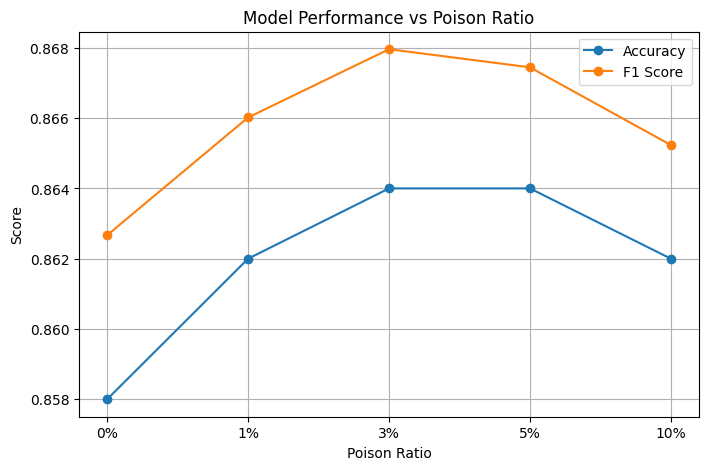

In [ ]:
# =========================
# 13. Plot Accuracy and F1 Score
# =========================

plt.figure(figsize=(8, 5))
plt.plot(results_df["Poison Ratio"], results_df["Accuracy"], marker="o", label="Accuracy")
plt.plot(results_df["Poison Ratio"], results_df["F1 Score"], marker="o", label="F1 Score")
plt.xlabel("Poison Ratio")
plt.ylabel("Score")
plt.title("Model Performance vs Poison Ratio")
plt.legend()
plt.grid(True)
plt.show()

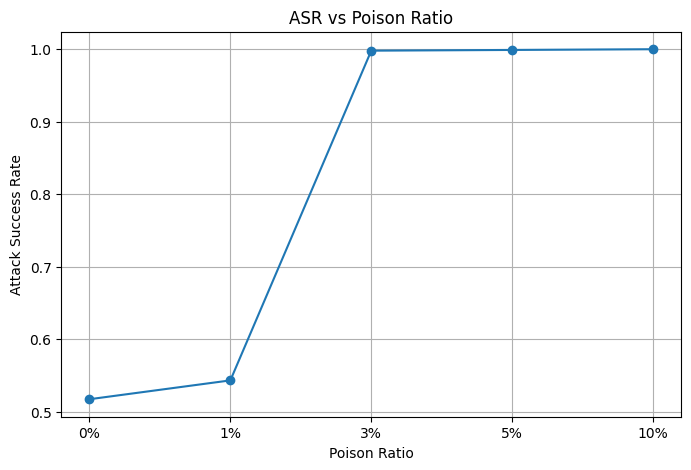

In [ ]:
# =========================
# 14. Plot Attack Success Rate
# =========================

plt.figure(figsize=(8, 5))
plt.plot(results_df["Poison Ratio"], results_df["ASR"], marker="o")
plt.xlabel("Poison Ratio")
plt.ylabel("Attack Success Rate")
plt.title("ASR vs Poison Ratio")
plt.grid(True)
plt.show()

In [ ]:
# =========================
# 15. Simple Mitigation: Known Trigger Filtering
# =========================

def remove_trigger_samples(dataset):
    filtered_data = []

    for item in dataset:
        if TRIGGER_WORD not in item["text"].split():
            filtered_data.append(item)

    return Dataset.from_list(filtered_data)

In [ ]:
# =========================
# 16. Apply Mitigation on 10% Poisoned Dataset
# =========================

poisoned_10 = poison_dataset(train_data, 0.10)

print("Before mitigation:", len(poisoned_10))

mitigated_train = remove_trigger_samples(poisoned_10)

print("After mitigation:", len(mitigated_train))

tokenized_mitigated_train = tokenize_dataset(mitigated_train)

mitigated_model, mitigated_trainer, mitigated_results = train_model(
    tokenized_mitigated_train,
    tokenized_test,
    "./mitigated_model"
)

mitigated_asr = calculate_asr(mitigated_model, test_data)

print("Mitigated Model Results:")
print(mitigated_results)
print("Mitigated ASR:", mitigated_asr)

Before mitigation: 5000
After mitigation: 4500


Map:   0%|          | 0/4500 [00:00<?, ? examples/s]

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Step,Training Loss
50,0.626859
100,0.459165
150,0.409364
200,0.382089
250,0.371611
300,0.364962
350,0.277355
400,0.262975
450,0.262011
500,0.241710


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Training Loss,Validation Loss,Step,Accuracy,Precision,Recall,F1
0.221849,0.349966,564,0.863000,0.849711,0.882000,0.865554


Mitigated Model Results:
{'eval_loss': 0.3499661386013031, 'eval_accuracy': 0.863, 'eval_precision': 0.8497109826589595, 'eval_recall': 0.882, 'eval_f1': 0.8655544651619235}
Mitigated ASR: 0.511


In [ ]:
# =========================
# 17. Final Comparison Table
# =========================

final_comparison = pd.DataFrame([
    {
        "Model": "Clean Model",
        "Accuracy": clean_results["eval_accuracy"],
        "Precision": clean_results["eval_precision"],
        "Recall": clean_results["eval_recall"],
        "F1 Score": clean_results["eval_f1"],
        "ASR": clean_asr
    },
    {
        "Model": "Poisoned Model 10%",
        "Accuracy": results_df[results_df["Poison Ratio"] == "10%"]["Accuracy"].values[0],
        "Precision": results_df[results_df["Poison Ratio"] == "10%"]["Precision"].values[0],
        "Recall": results_df[results_df["Poison Ratio"] == "10%"]["Recall"].values[0],
        "F1 Score": results_df[results_df["Poison Ratio"] == "10%"]["F1 Score"].values[0],
        "ASR": results_df[results_df["Poison Ratio"] == "10%"]["ASR"].values[0]
    },
    {
        "Model": "Mitigated Model",
        "Accuracy": mitigated_results["eval_accuracy"],
        "Precision": mitigated_results["eval_precision"],
        "Recall": mitigated_results["eval_recall"],
        "F1 Score": mitigated_results["eval_f1"],
        "ASR": mitigated_asr
    }
])

final_comparison

,Model,Accuracy,Precision,Recall,F1 Score,ASR
0,Clean Model,0.858,0.835206,0.892,0.862669,0.517
1,Poisoned Model 10%,0.862,0.845420,0.886,0.865234,1.000
2,Mitigated Model,0.863,0.849711,0.882,0.865554,0.511


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

results_df = pd.DataFrame([
    {"Poison Ratio": "0%", "Accuracy": 0.858, "Precision": 0.835206, "Recall": 0.892, "F1 Score": 0.862669, "ASR": 0.517},
    {"Poison Ratio": "1%", "Accuracy": 0.862, "Precision": 0.841509, "Recall": 0.892, "F1 Score": 0.866019, "ASR": 0.543},
    {"Poison Ratio": "3%", "Accuracy": 0.864, "Precision": 0.843396, "Recall": 0.894, "F1 Score": 0.867961, "ASR": 0.998},
    {"Poison Ratio": "5%", "Accuracy": 0.864, "Precision": 0.846008, "Recall": 0.890, "F1 Score": 0.867446, "ASR": 0.999},
    {"Poison Ratio": "10%", "Accuracy": 0.862, "Precision": 0.845420, "Recall": 0.886, "F1 Score": 0.865234, "ASR": 1.000},
])

final_comparison = pd.DataFrame([
    {"Model": "Clean Model", "Accuracy": 0.858, "Precision": 0.835206, "Recall": 0.892, "F1 Score": 0.862669, "ASR": 0.517},
    {"Model": "Poisoned Model 10%", "Accuracy": 0.862, "Precision": 0.845420, "Recall": 0.886, "F1 Score": 0.865234, "ASR": 1.000},
    {"Model": "Mitigated Model", "Accuracy": 0.863, "Precision": 0.849711, "Recall": 0.882, "F1 Score": 0.865554, "ASR": 0.511},
])

results_df

,Poison Ratio,Accuracy,Precision,Recall,F1 Score,ASR
0,0%,0.858,0.835206,0.892,0.862669,0.517
1,1%,0.862,0.841509,0.892,0.866019,0.543
2,3%,0.864,0.843396,0.894,0.867961,0.998
3,5%,0.864,0.846008,0.890,0.867446,0.999
4,10%,0.862,0.845420,0.886,0.865234,1.000


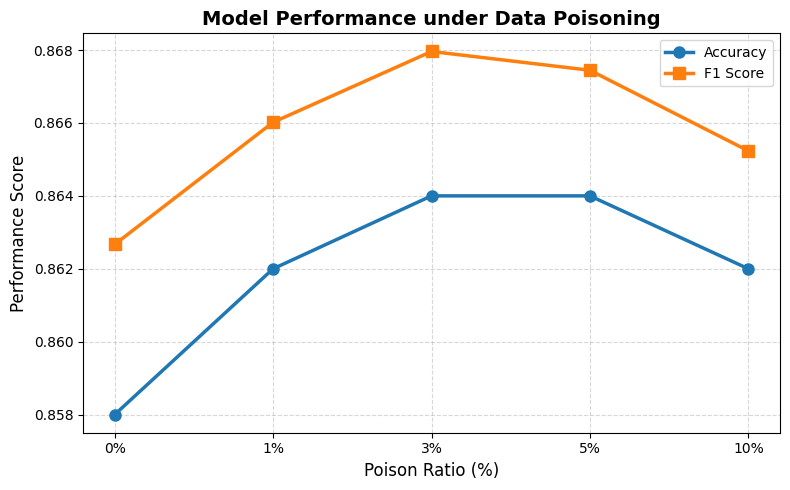

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

plt.plot(
    results_df["Poison Ratio"],
    results_df["Accuracy"],
    marker="o",
    markersize=8,
    linewidth=2.5,
    color="#1f77b4",
    label="Accuracy"
)

plt.plot(
    results_df["Poison Ratio"],
    results_df["F1 Score"],
    marker="s",
    markersize=8,
    linewidth=2.5,
    color="#ff7f0e",
    label="F1 Score"
)

plt.xlabel("Poison Ratio (%)", fontsize=12)
plt.ylabel("Performance Score", fontsize=12)

plt.title(
    "Model Performance under Data Poisoning",
    fontsize=14,
    fontweight="bold"
)

plt.grid(True, linestyle="--", alpha=0.5)
plt.legend()

plt.tight_layout()

plt.savefig(
    "Accuracy_F1_Graph.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

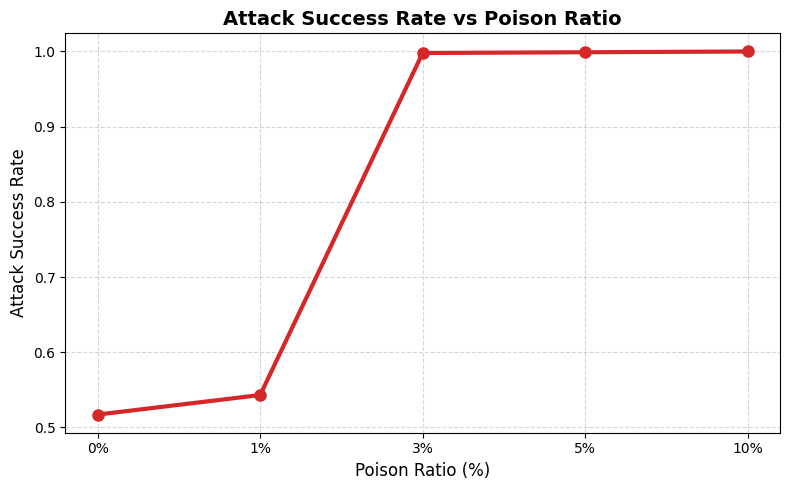

In [ ]:
plt.figure(figsize=(8,5))

plt.plot(
    results_df["Poison Ratio"],
    results_df["ASR"],
    marker="o",
    markersize=8,
    linewidth=3,
    color="#d62728"
)

plt.xlabel("Poison Ratio (%)", fontsize=12)
plt.ylabel("Attack Success Rate", fontsize=12)

plt.title(
    "Attack Success Rate vs Poison Ratio",
    fontsize=14,
    fontweight="bold"
)

plt.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()

plt.savefig(
    "ASR_Graph.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

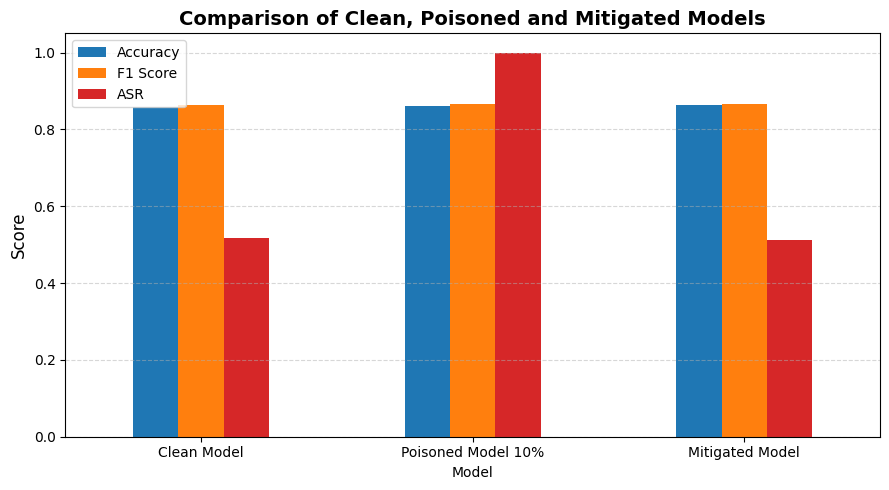

In [ ]:
ax = final_comparison.set_index("Model")[
    ["Accuracy", "F1 Score", "ASR"]
].plot(
    kind="bar",
    figsize=(9,5),
    color=["#1f77b4", "#ff7f0e", "#d62728"]
)

plt.title(
    "Comparison of Clean, Poisoned and Mitigated Models",
    fontsize=14,
    fontweight="bold"
)

plt.ylabel("Score", fontsize=12)

plt.xticks(rotation=0)

plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.5
)

plt.legend(loc="upper left")

plt.tight_layout()

plt.savefig(
    "Final_Comparison_Graph.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

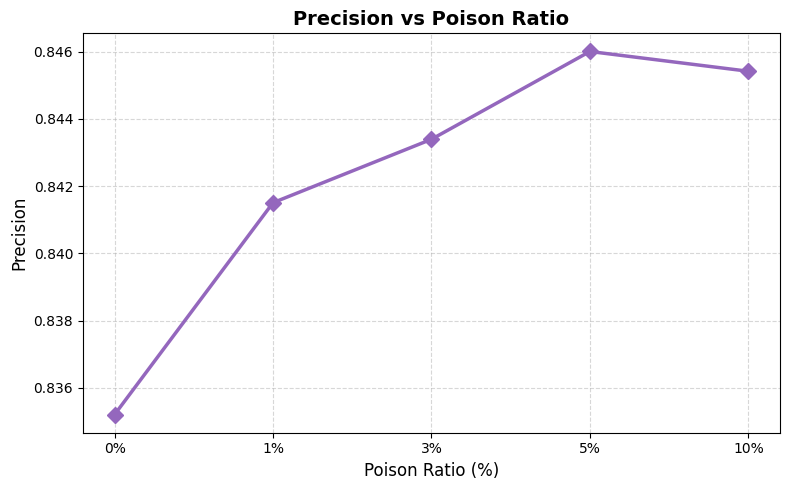

In [ ]:
plt.figure(figsize=(8,5))

plt.plot(
    results_df["Poison Ratio"],
    results_df["Precision"],
    marker="D",
    markersize=8,
    linewidth=2.5,
    color="#9467bd"
)

plt.xlabel("Poison Ratio (%)", fontsize=12)
plt.ylabel("Precision", fontsize=12)
plt.title("Precision vs Poison Ratio", fontsize=14, fontweight="bold")
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.savefig("Precision_Graph.png", dpi=300, bbox_inches="tight")
plt.show()

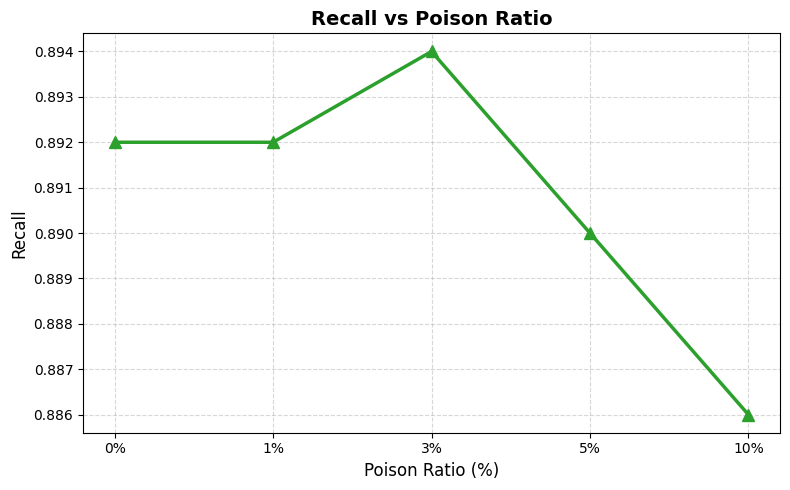

In [ ]:
plt.figure(figsize=(8,5))

plt.plot(
    results_df["Poison Ratio"],
    results_df["Recall"],
    marker="^",
    markersize=8,
    linewidth=2.5,
    color="#2ca02c"
)

plt.xlabel("Poison Ratio (%)", fontsize=12)
plt.ylabel("Recall", fontsize=12)
plt.title("Recall vs Poison Ratio", fontsize=14, fontweight="bold")
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.savefig("Recall_Graph.png", dpi=300, bbox_inches="tight")
plt.show()

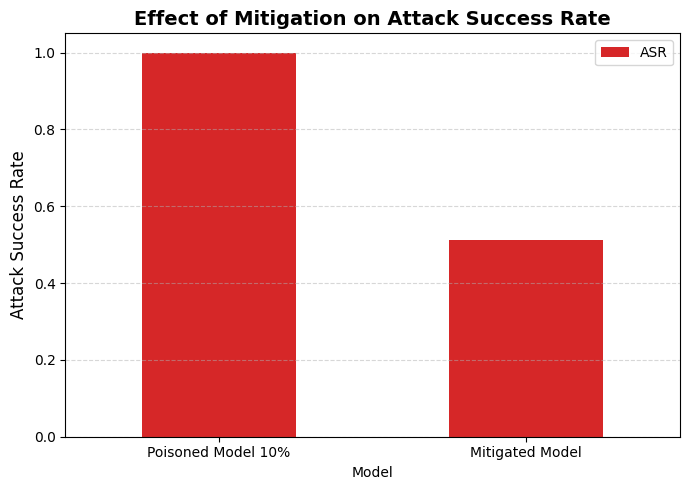

In [ ]:
mitigation_df = final_comparison[final_comparison["Model"].isin(
    ["Poisoned Model 10%", "Mitigated Model"]
)]

ax = mitigation_df.set_index("Model")[["ASR"]].plot(
    kind="bar",
    figsize=(7,5),
    color=["#d62728"]
)

plt.title("Effect of Mitigation on Attack Success Rate", fontsize=14, fontweight="bold")
plt.ylabel("Attack Success Rate", fontsize=12)
plt.xticks(rotation=0)
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.savefig("Mitigation_ASR_Graph.png", dpi=300, bbox_inches="tight")
plt.show()

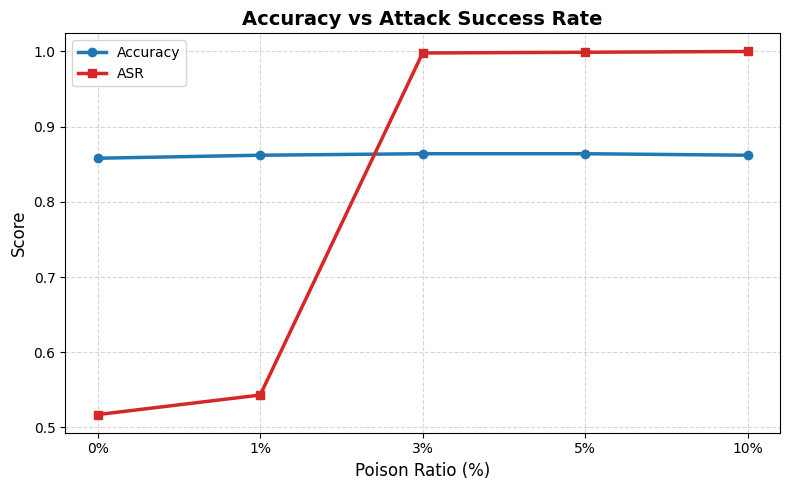

In [ ]:
plt.figure(figsize=(8,5))

plt.plot(
    results_df["Poison Ratio"],
    results_df["Accuracy"],
    marker="o",
    linewidth=2.5,
    color="#1f77b4",
    label="Accuracy"
)

plt.plot(
    results_df["Poison Ratio"],
    results_df["ASR"],
    marker="s",
    linewidth=2.5,
    color="#d62728",
    label="ASR"
)

plt.xlabel("Poison Ratio (%)", fontsize=12)
plt.ylabel("Score", fontsize=12)
plt.title("Accuracy vs Attack Success Rate", fontsize=14, fontweight="bold")
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend()
plt.tight_layout()
plt.savefig("Accuracy_vs_ASR_Graph.png", dpi=300, bbox_inches="tight")
plt.show()